# Análise Angular da Simulação SWGO — Múon de 5 GeV no WCD
**Dissertação de Mestrado em Física**

Simulação Geant4 11.1.3 — Múon de 5 GeV com inclinações: 0°, 10°, 15°, 30°, 45°, 60°  
Detector: WCD cilíndrico (r=170 cm, h=187.87 cm) com revestimento Tyvek  
4 PMTs (3 no fundo em triângulo equilátero + 1 no topo)

---

**Objetivo:** Verificar a consistência dos ângulos maiores e estudar como a resposta do detector varia com o ângulo zenital do múon.

## 1. Importações e Configurações

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.optimize import curve_fit
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Estilo acadêmico profissional (idêntico ao notebook vertical)
sns.set_theme(style='ticks', palette='colorblind')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 13,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'axes.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'legend.framealpha': 0.9,
    'legend.edgecolor': '0.8',
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

palette = sns.color_palette('muted')

# Ângulos simulados
ANGULOS = [0, 10, 15, 30, 45, 60]

# Paleta de cores por ângulo (consistente em todos os plots)
CORES_ANGULO = {
    0:  palette[0],
    10: palette[1],
    15: palette[2],
    30: palette[3],
    45: palette[4],
    60: palette[5],
}

print('Configurações carregadas com sucesso.')
print(f'Ângulos a analisar: {ANGULOS}')

Configurações carregadas com sucesso.
Ângulos a analisar: [0, 10, 15, 30, 45, 60]


## 2. Funções Auxiliares

In [3]:
def gaussian(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

def landau_approx(x, A, mu, sigma):
    """Aproximação numérica da distribuição de Landau"""
    lam = (x - mu) / sigma
    return A * np.exp(-0.5 * (lam + np.exp(-lam))) / np.sqrt(2 * np.pi)

def format_value_error(val, err):
    """Formata valor ± erro com casas decimais consistentes"""
    if err == 0 or np.isnan(err):
        return f'{val:.2f}', '—'
    mag = int(np.floor(np.log10(abs(err))))
    decimals = max(0, -mag + 1)
    fmt = f'{{:.{decimals}f}}'
    return fmt.format(val), fmt.format(err)

def fit_and_plot(ax, data, bins, color, fit_func='gaussian', label='',
                 text_x=0.97, text_y=0.97, text_ha='right',
                 n_total=None, n_filtered=0, unit=''):
    """Plota histograma com ajuste e parâmetros na caixa de texto"""
    counts, edges = np.histogram(data, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    width = edges[1] - edges[0]

    ax.bar(centers, counts, width=width * 0.9, color=color, alpha=0.8,
           edgecolor='black', linewidth=0.5, label='Simulação')

    try:
        if fit_func == 'gaussian':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(gaussian, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, gaussian(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Gaussiano')
            mu_str, mu_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (f'Dados do ajuste:\n'
                       f'$\\mu$ = {mu_str} ± {mu_err_str}{" " + unit if unit else ""}\n'
                       f'$\\sigma$ = {sig_str} ± {sig_err_str}\n'
                       f'N = {n_display}')
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        elif fit_func == 'landau':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(landau_approx, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, landau_approx(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Landau')
            mpv_str, mpv_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (f'Dados do ajuste:\n'
                       f'MPV = {mpv_str} ± {mpv_err_str}{" " + unit if unit else ""}\n'
                       f'$\\sigma$ = {sig_str} ± {sig_err_str}\n'
                       f'N = {n_display}')
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        props = dict(boxstyle='round', facecolor='white', alpha=0.5)
        ax.text(text_x, text_y, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', horizontalalignment=text_ha, bbox=props)
    except Exception as e:
        print(f'Ajuste falhou: {e}')

    return ax


def caminho_por_angulo(angulo):
    """
    Comprimento do trajeto geométrico do múon dentro do WCD em função do ângulo zenital.
    Para múon passante pelo eixo central:
      - vertical (0°): percorre a altura H
      - inclinado: percorre H / cos(theta), limitado pelo raio do cilindro
    """
    H = 187.87  # cm — altura do WCD
    R = 170.0   # cm — raio do WCD
    theta = np.radians(angulo)
    if theta == 0:
        return H
    # Comprimento pela vertical
    L_vertical = H / np.cos(theta)
    # Comprimento máximo pela parede lateral (diâmetro / sin(theta))
    L_lateral = 2 * R / np.sin(theta)
    return min(L_vertical, L_lateral)

print('Funções auxiliares definidas.')

Funções auxiliares definidas.


## 3. Carregamento dos Dados

**Convenção de nomenclatura esperada:**
```
SWGO_muon5GeV_<angulo>deg_1000ev_nt_Data.csv
SWGO_muon5GeV_<angulo>deg_1000ev_nt_PMTData.csv
SWGO_muon5GeV_<angulo>deg_1000ev_nt_HodoData.csv
```
Ajuste `DATA_DIR` e o template de nome conforme seus arquivos.

In [4]:
# ─── CONFIGURAR AQUI ───────────────────────────────────────────────────────────
DATA_DIR = r'C:\Users\gizel\OneDrive\Área de Trabalho\Análises\Muon_angular\v01'

# Templates de nome — use {ang} como placeholder do ângulo (ex.: 'vertical' ou '10deg')
# Exemplo se o arquivo vertical continua com o nome original:
def nome_data(ang):
    sufixo = 'vertical' if ang == 0 else f'{ang}deg'
    return f'SWGO_muon5GeV_{sufixo}_1000ev_nt_Data.csv'

def nome_pmt(ang):
    sufixo = 'vertical' if ang == 0 else f'{ang}deg'
    return f'SWGO_muon5GeV_{sufixo}_1000ev_nt_PMTData.csv'

def nome_hodo(ang):
    sufixo = 'vertical' if ang == 0 else f'{ang}deg'
    return f'SWGO_muon5GeV_{sufixo}_1000ev_nt_HodoData.csv'
# ──────────────────────────────────────────────────────────────────────────────

import os

COLUNAS_DATA = [
    'iEventID', 'EnergyDeposited_MeV', 'PositionX_cm', 'PositionY_cm',
    'PositionZ_cm', 'Time_ns', 'EnergyElectronSec_MeV', 'nElectronSec',
    'nCerenkovByMuon', 'nCerenkovByElectron', 'EdepGammas_MeV', 'EdepTrack_MeV'
]
COLUNAS_PMT  = ['iEventID', 'nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3', 'nFotonsPMT4']
COLUNAS_HODO = ['iEventID', 'ColumnID', 'RowID', 'Edep_MeV', 'Time_ns']

dados = {}   # dados[ang] = {'df': ..., 'df_pmt': ..., 'df_hodo': ..., 'df_all': ...}

for ang in ANGULOS:
    path_data = os.path.join(DATA_DIR, nome_data(ang))
    path_pmt  = os.path.join(DATA_DIR, nome_pmt(ang))
    path_hodo = os.path.join(DATA_DIR, nome_hodo(ang))

    try:
        df      = pd.read_csv(path_data, comment='#', header=None, names=COLUNAS_DATA)
        df_pmt  = pd.read_csv(path_pmt,  comment='#', header=None, names=COLUNAS_PMT)
        df_hodo = pd.read_csv(path_hodo, comment='#', header=None, names=COLUNAS_HODO)

        df_pmt['nFotonsTotal'] = df_pmt['nFotonsPMT1'] + df_pmt['nFotonsPMT2'] + df_pmt['nFotonsPMT3']
        df_all = df.merge(df_pmt, on='iEventID')
        df_all['nCerenkovTotal'] = df_all['nCerenkovByMuon'] + df_all['nCerenkovByElectron']
        df_all['eficiencia']     = df_all['nFotonsTotal'] / df_all['nCerenkovTotal'] * 100

        dados[ang] = {'df': df, 'df_pmt': df_pmt, 'df_hodo': df_hodo, 'df_all': df_all}
        print(f'  θ = {ang:2d}°  →  {len(df)} eventos carregados')

    except FileNotFoundError as e:
        print(f'  θ = {ang:2d}°  →  ARQUIVO NÃO ENCONTRADO: {e}')

print(f'\nTotal de ângulos carregados: {len(dados)}/{len(ANGULOS)}')

  θ =  0°  →  1000 eventos carregados
  θ = 10°  →  1000 eventos carregados
  θ = 15°  →  1000 eventos carregados
  θ = 30°  →  1000 eventos carregados
  θ = 45°  →  1000 eventos carregados
  θ = 60°  →  1000 eventos carregados

Total de ângulos carregados: 6/6


## 4. Verificação de Sanidade dos Dados Angulares

Antes de qualquer análise, temos que verificar se os dados dos ângulos maiores são fisicamente consistentes:
- O trajeto aumenta com o ângulo → energia depositada deve aumentar
- Número de fótons Cherenkov deve escalar com o trajeto
- A eficiência de detecção pode cair em ângulos extremos (múon sai pela lateral)

In [5]:
print('=' * 70)
print(f'{"θ":>5} | {"L_traj (cm)":>12} | {"Edep média (MeV)":>17} | {"Cer. total":>11} | {"Ef. (%)": >9} | N')
print('-' * 70)

resumo_angular = []

for ang in ANGULOS:
    if ang not in dados:
        continue
    d = dados[ang]
    L = caminho_por_angulo(ang)
    edep_mean  = d['df']['EnergyDeposited_MeV'].mean()
    edep_std   = d['df']['EnergyDeposited_MeV'].std()
    cer_mean   = d['df_all']['nCerenkovTotal'].mean()
    ef_mean    = d['df_all']['eficiencia'].mean()
    N          = len(d['df'])

    print(f'{ang:>4}° | {L:>12.1f} | {edep_mean:>10.2f} ± {edep_std:<5.2f} | {cer_mean:>11.0f} | {ef_mean:>8.2f}% | {N}')

    resumo_angular.append({
        'angulo': ang,
        'L_cm': L,
        'cos_theta': np.cos(np.radians(ang)),
        'edep_mean': edep_mean,
        'edep_std': edep_std,
        'cer_mean': cer_mean,
        'ef_mean': ef_mean,
        'pmt1_mean': d['df_pmt']['nFotonsPMT1'].mean(),
        'pmt2_mean': d['df_pmt']['nFotonsPMT2'].mean(),
        'pmt3_mean': d['df_pmt']['nFotonsPMT3'].mean(),
        'total_mean': d['df_pmt']['nFotonsTotal'].mean(),
        'N': N,
    })

print('=' * 70)
df_resumo = pd.DataFrame(resumo_angular)

# Verifica monotonicidade (sanidade física)
edep_vals = df_resumo['edep_mean'].values
monotono = all(edep_vals[i] <= edep_vals[i+1] for i in range(len(edep_vals)-1))
print(f'\n✔ Energia depositada aumenta monotonicamente com θ? {"SIM" if monotono else "NÃO — verificar!"}' )

    θ |  L_traj (cm) |  Edep média (MeV) |  Cer. total |   Ef. (%) | N
----------------------------------------------------------------------
   0° |        187.9 |     411.25 ± 83.99 |       74742 |     0.58% | 1000
  10° |        190.8 |     423.05 ± 101.15 |       76203 |     0.62% | 1000
  15° |        194.5 |     457.86 ± 97.01 |       82496 |     0.74% | 1000
  30° |        216.9 |     507.51 ± 100.18 |       91594 |     0.67% | 1000
  45° |        265.7 |     561.85 ± 87.38 |      101764 |     0.71% | 1000
  60° |        375.7 |     876.16 ± 117.68 |      158388 |     0.66% | 1000

✔ Energia depositada aumenta monotonicamente com θ? SIM


## 5. Distribuições por Ângulo — Energia Depositada

Para cada ângulo, plotamos a distribuição de Landau da energia depositada.  
O MPV (Most Probable Value) deve crescer com 1/cos(θ).

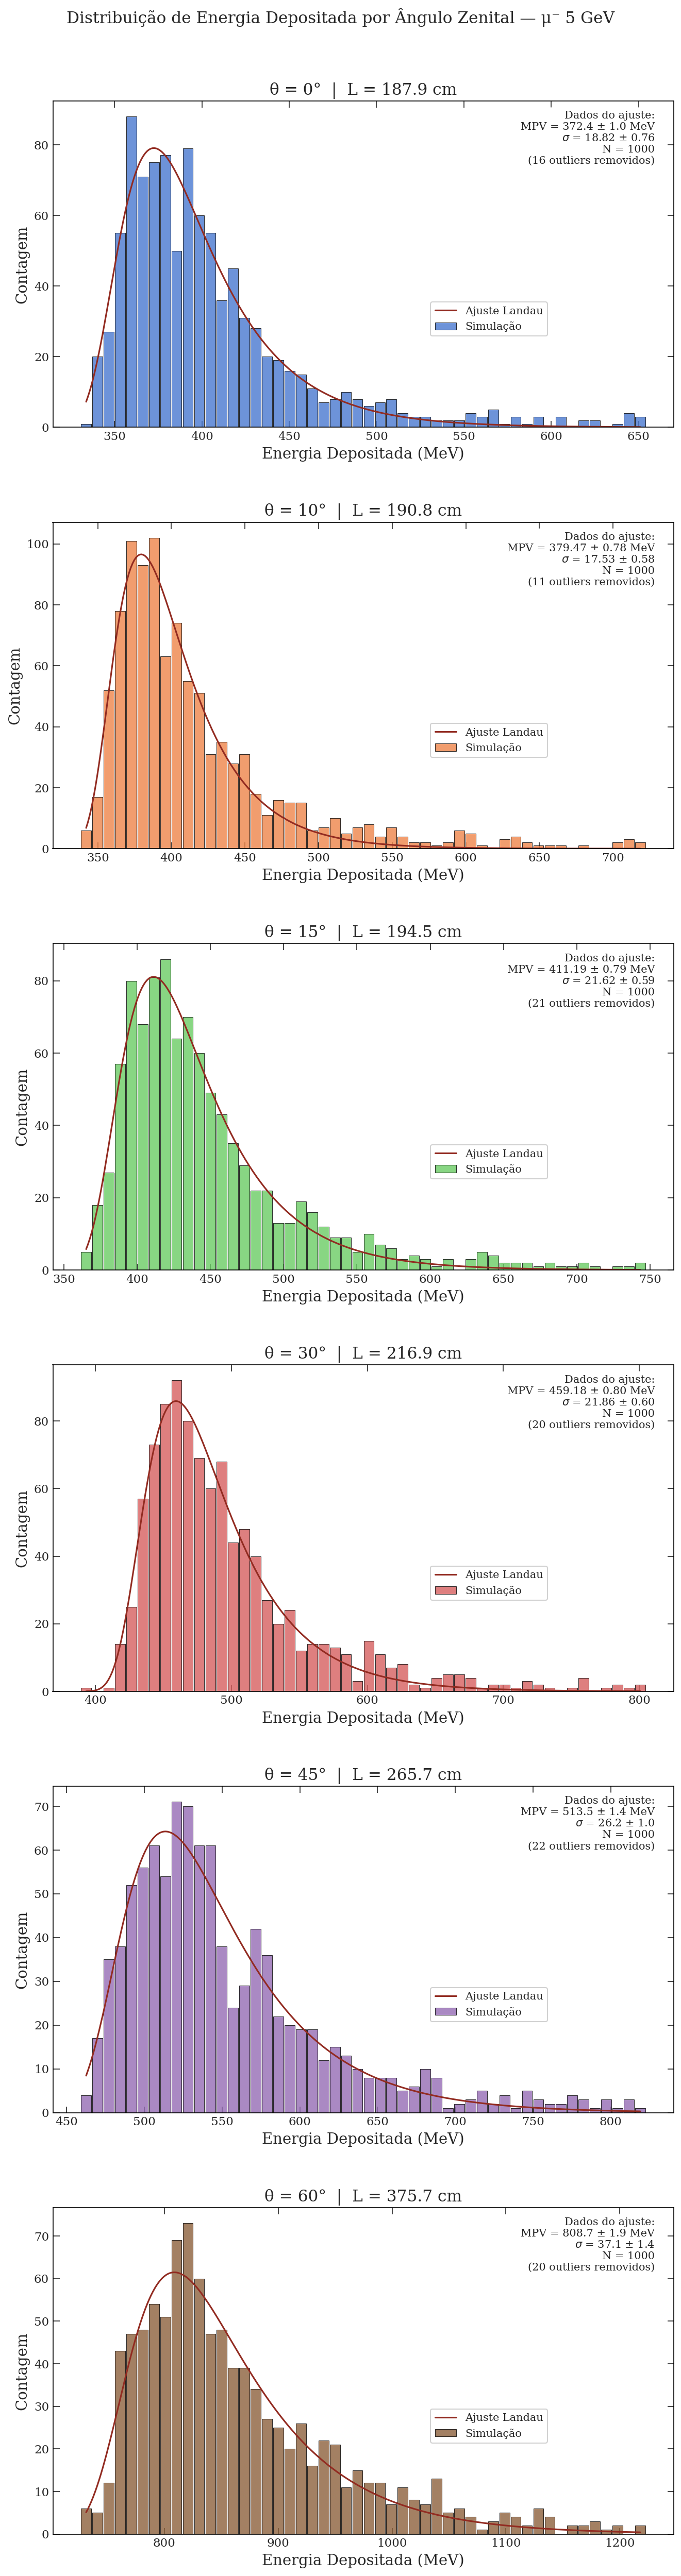

In [6]:
n_ang = len(dados)
n_cols = 1
n_rows = n_ang

fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, 5.5 * n_rows))
axes = axes.flatten()

for i, ang in enumerate(sorted(dados.keys())):
    ax = axes[i]
    edep = dados[ang]['df']['EnergyDeposited_MeV']
    edep_filt = edep[edep < edep.mean() + 3 * edep.std()]
    fit_and_plot(ax, edep_filt, bins=50, color=CORES_ANGULO[ang],
                 fit_func='landau', text_x=0.97, text_y=0.97, text_ha='right',
                 n_total=len(edep), n_filtered=len(edep) - len(edep_filt), unit='MeV')
    ax.set_xlabel('Energia Depositada (MeV)')
    ax.set_ylabel('Contagem')
    ax.set_title(f'θ = {ang}°  |  L = {caminho_por_angulo(ang):.1f} cm')
    ax.legend(fontsize=10, bbox_to_anchor=(0.6, 0.4), loc='upper left') #tirando de cima dos dados
    #ax.legend(fontsize=9, loc='upper right')

# Apaga subplots extras
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribuição de Energia Depositada por Ângulo Zenital — μ⁻ 5 GeV', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3)
plt.savefig('angular_energia_depositada.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_energia_depositada.pdf', bbox_inches='tight')
plt.show()

## 6. Distribuições por Ângulo — Fótons Detectados pelas PMTs

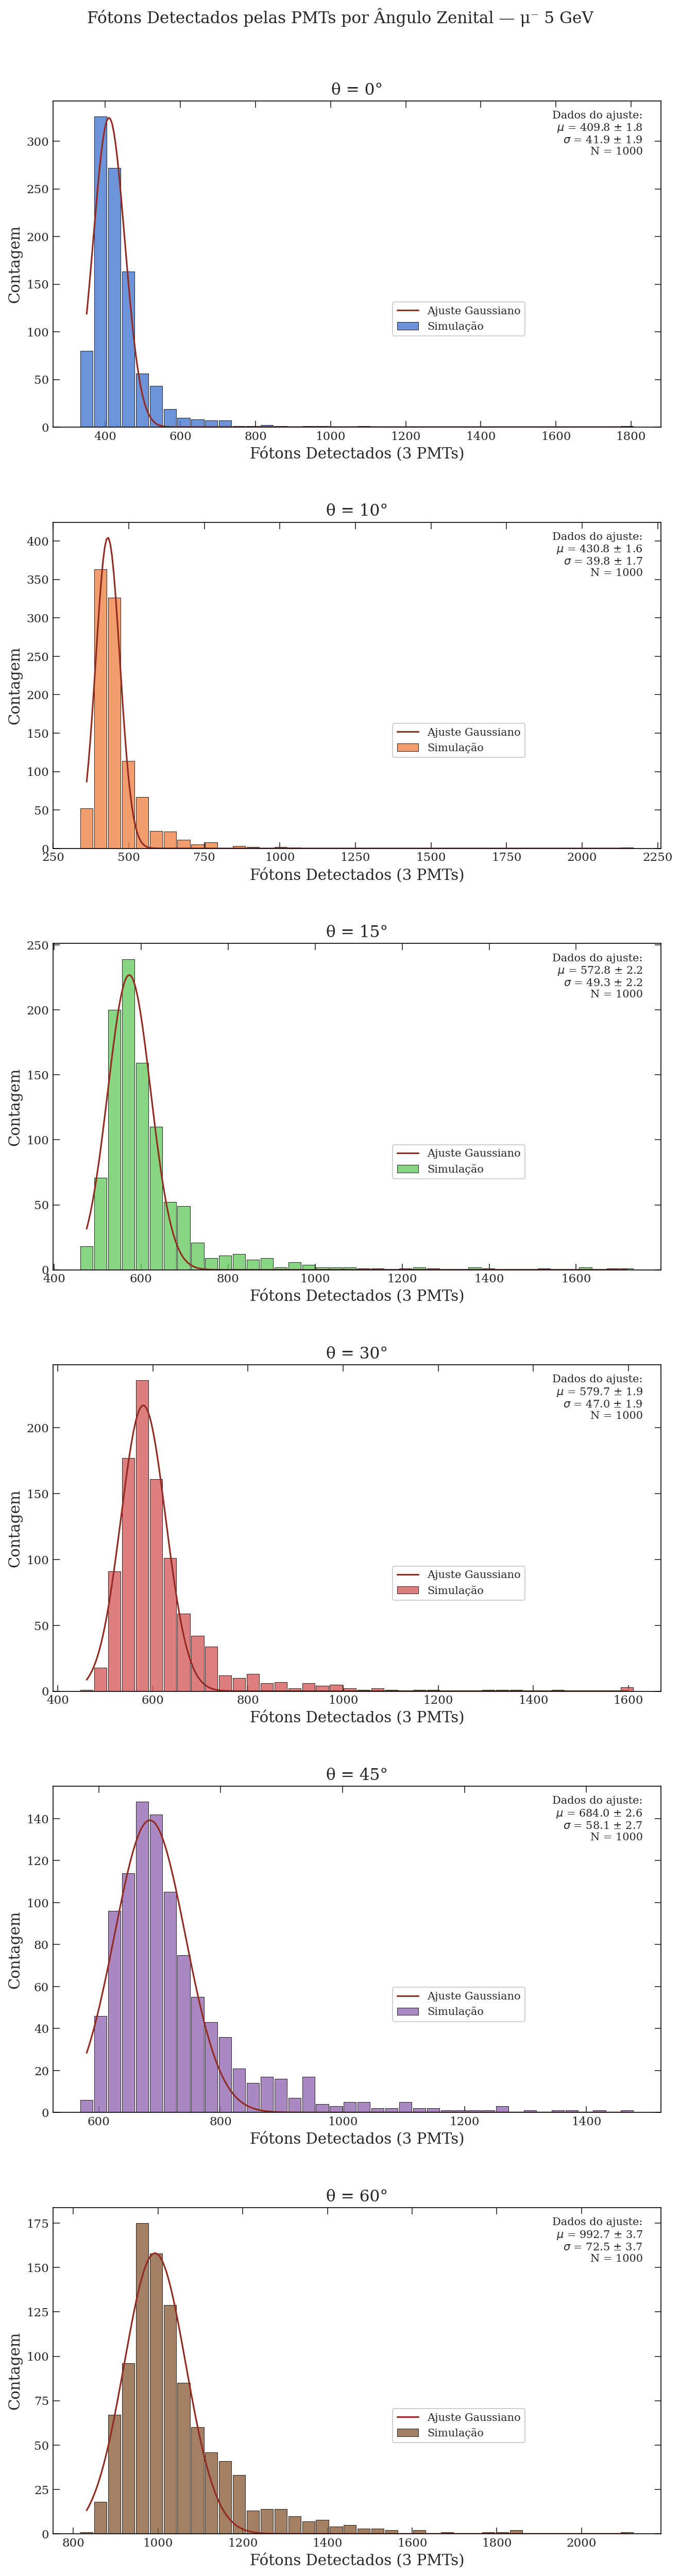

In [7]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, 5.5 * n_rows))
axes = axes.flatten()

for i, ang in enumerate(sorted(dados.keys())):
    ax = axes[i]
    total = dados[ang]['df_pmt']['nFotonsTotal']
    fit_and_plot(ax, total, bins=40, color=CORES_ANGULO[ang],
                 fit_func='gaussian', text_x=0.97, text_y=0.97, text_ha='right')
    ax.set_xlabel('Fótons Detectados (3 PMTs)')
    ax.set_ylabel('Contagem')
    ax.set_title(f'θ = {ang}°')
    ax.legend(fontsize=10, bbox_to_anchor=(0.55, 0.4), loc='upper left')
    
    #ax.legend(fontsize=9, loc='upper right')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Fótons Detectados pelas PMTs por Ângulo Zenital — μ⁻ 5 GeV', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3)
plt.savefig('angular_fotons_pmt.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_fotons_pmt.pdf', bbox_inches='tight')
plt.show()

## 7. Evolução das Grandezas com o Ângulo (Plots Comparativos)

Aqui comparamos todas as grandezas físicas em função de θ para verificar a consistência.

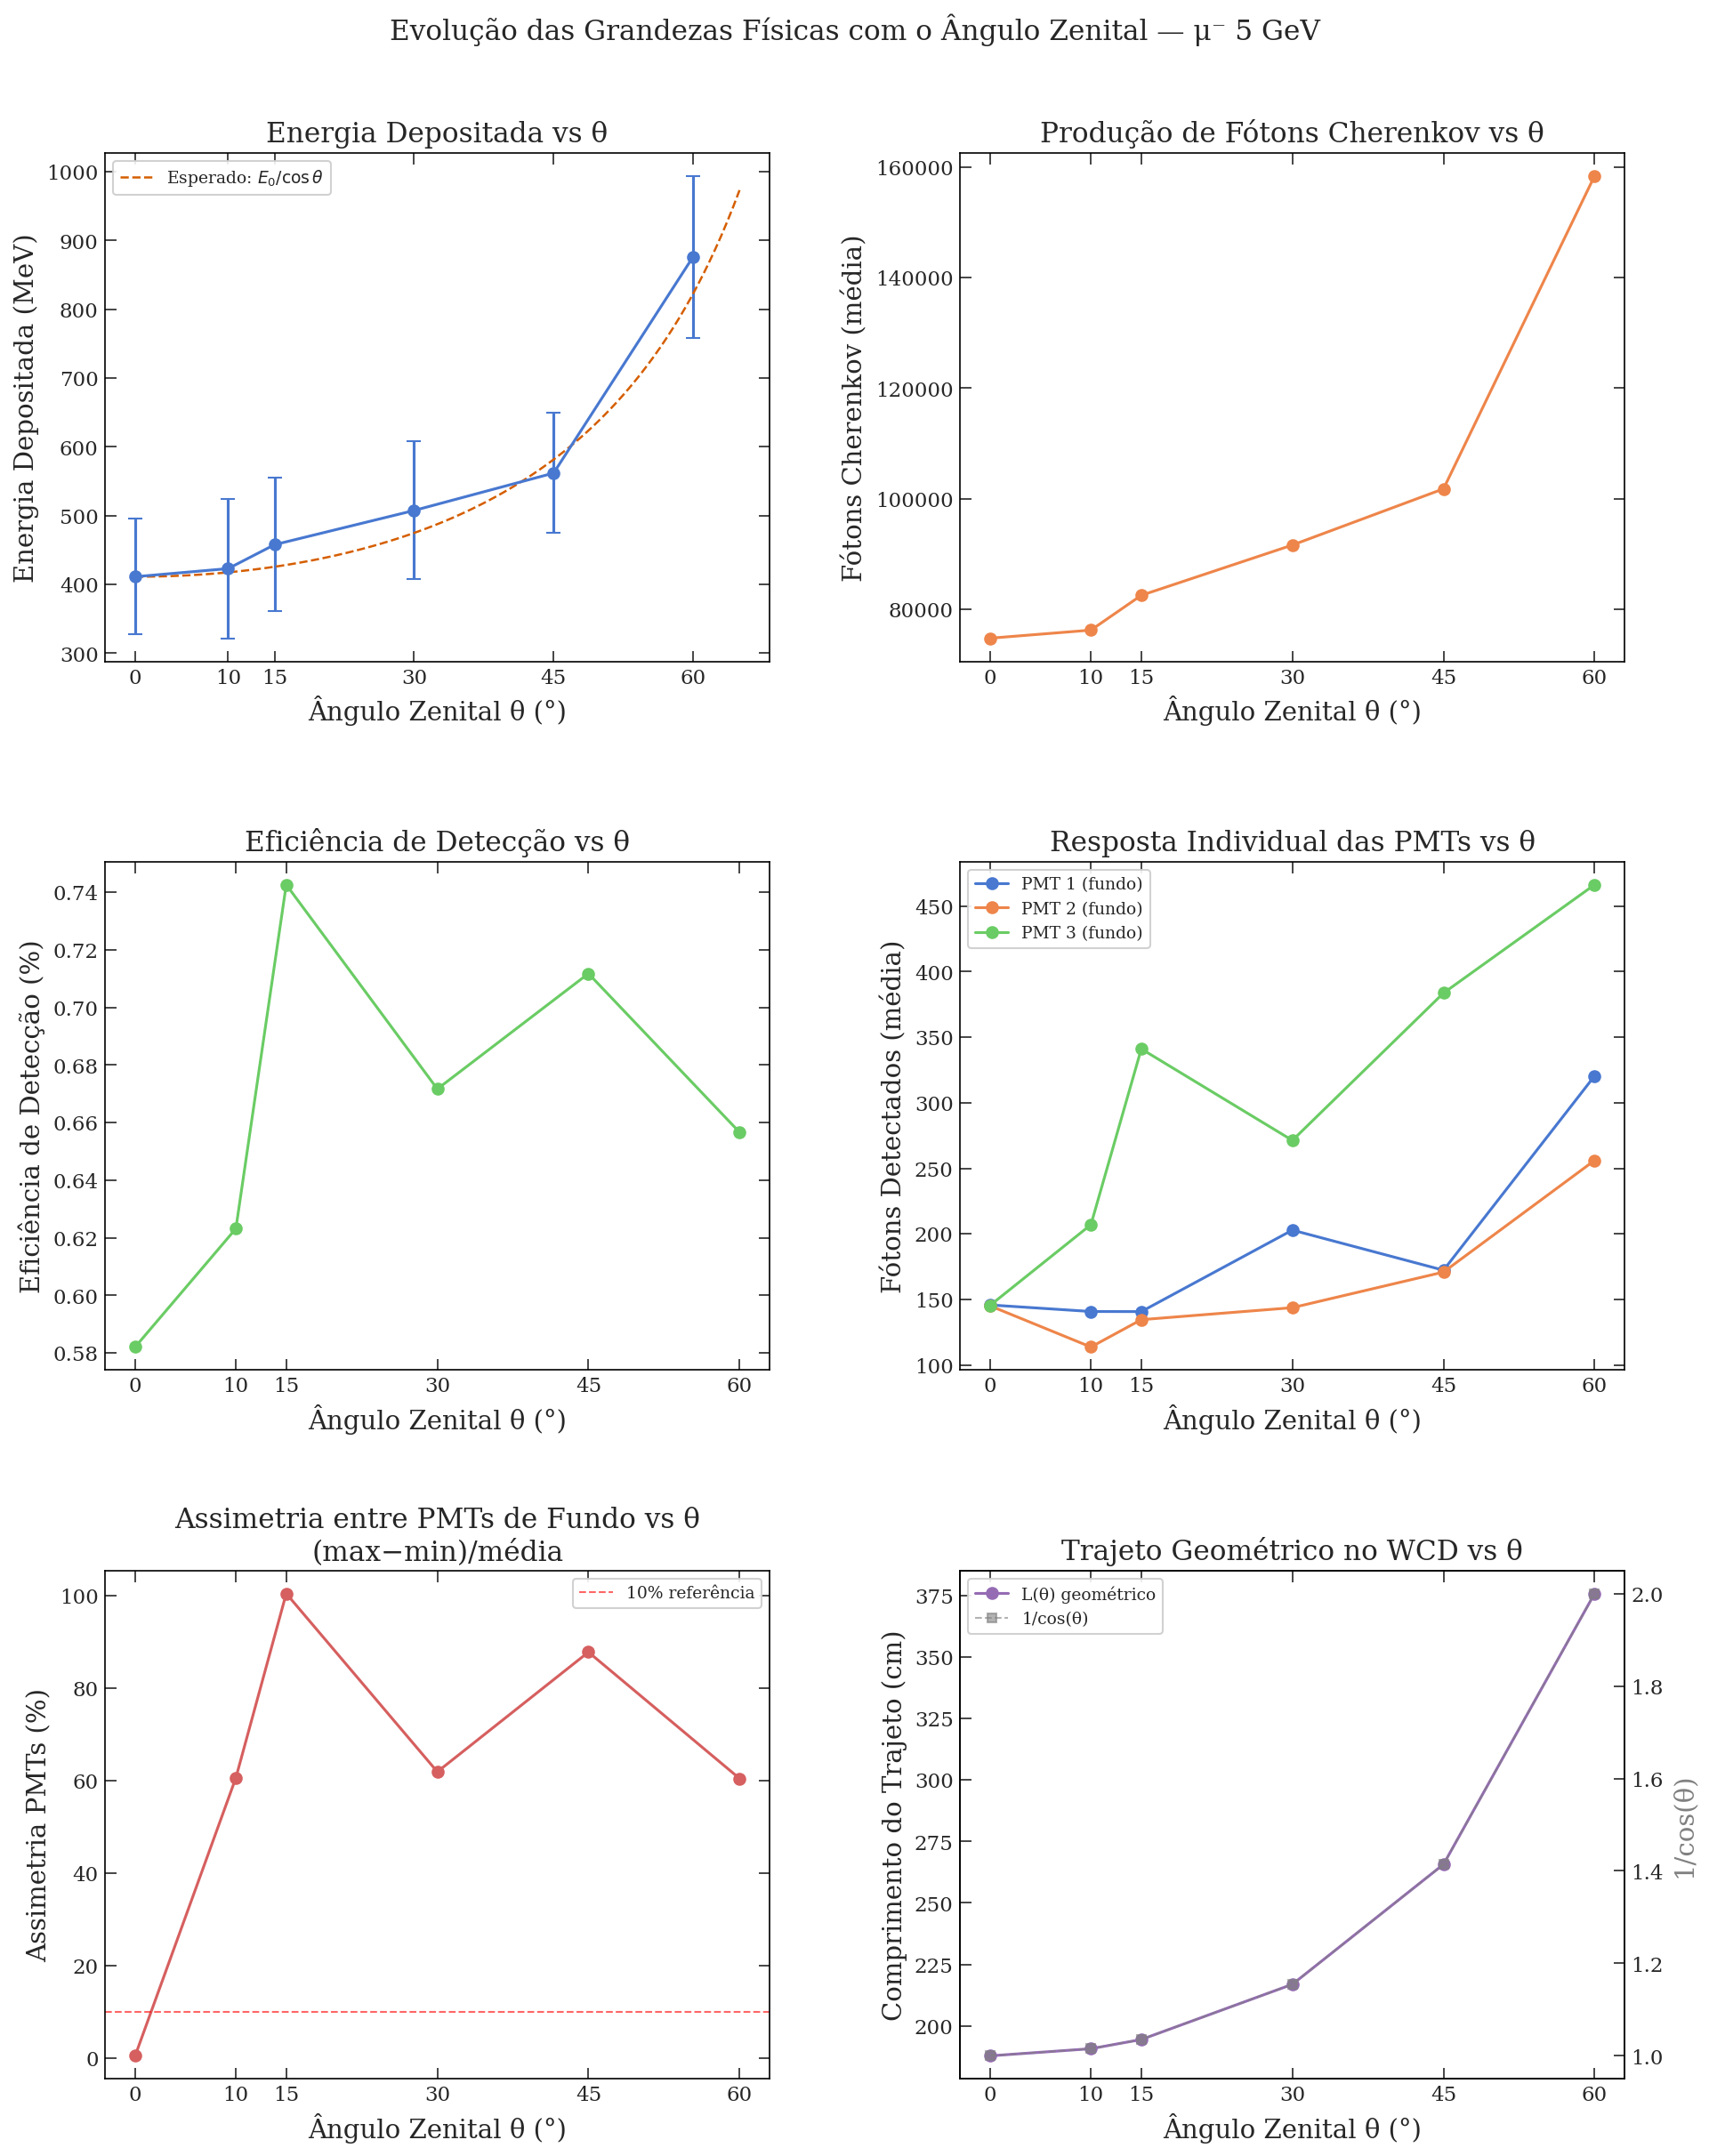

In [8]:
df_res = df_resumo.set_index('angulo')
angulos_list = sorted(dados.keys())
cores_list = [CORES_ANGULO[a] for a in angulos_list]

fig, axes = plt.subplots(3, 2, figsize=(13, 16))

# ── 1. Energia depositada vs θ ─────────────────────────────────────────────
ax = axes[0, 0]
ax.errorbar(angulos_list, df_res.loc[angulos_list, 'edep_mean'],
            yerr=df_res.loc[angulos_list, 'edep_std'],
            fmt='o-', color=palette[0], capsize=4, linewidth=1.5, markersize=6)
# Curva teórica: Edep(0) / cos(θ)
edep0 = df_res.loc[0, 'edep_mean'] if 0 in df_res.index else None
if edep0:
    theta_th = np.linspace(0, 65, 100)
    ax.plot(theta_th, edep0 / np.cos(np.radians(theta_th)), 'r--',
            linewidth=1.2, label='Esperado: $E_0/\\cos\\theta$')
    ax.legend(fontsize=9)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Energia Depositada (MeV)')
ax.set_title('Energia Depositada vs θ')
ax.set_xticks(angulos_list)

# ── 2. Fótons Cherenkov totais vs θ ────────────────────────────────────────
ax = axes[0, 1]
ax.plot(angulos_list, df_res.loc[angulos_list, 'cer_mean'],
        'o-', color=palette[1], linewidth=1.5, markersize=6)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Fótons Cherenkov (média)')
ax.set_title('Produção de Fótons Cherenkov vs θ')
ax.set_xticks(angulos_list)

# ── 3. Eficiência de detecção vs θ ─────────────────────────────────────────
ax = axes[1, 0]
ax.plot(angulos_list, df_res.loc[angulos_list, 'ef_mean'],
        'o-', color=palette[2], linewidth=1.5, markersize=6)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Eficiência de Detecção (%)')
ax.set_title('Eficiência de Detecção vs θ')
ax.set_xticks(angulos_list)

# ── 4. Resposta por PMT vs θ ────────────────────────────────────────────────
ax = axes[1, 1]
for k, (pmt_col, cor, lbl) in enumerate(zip(
        ['pmt1_mean', 'pmt2_mean', 'pmt3_mean'],
        [palette[0], palette[1], palette[2]],
        ['PMT 1 (fundo)', 'PMT 2 (fundo)', 'PMT 3 (fundo)'])):
    ax.plot(angulos_list, df_res.loc[angulos_list, pmt_col],
            'o-', color=cor, linewidth=1.5, markersize=6, label=lbl)
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Fótons Detectados (média)')
ax.set_title('Resposta Individual das PMTs vs θ')
ax.set_xticks(angulos_list)
ax.legend(fontsize=9)

# ── 5. Assimetria entre PMTs vs θ ─────────────────────────────────────────
ax = axes[2, 0]
pmt_vals = df_res.loc[angulos_list, ['pmt1_mean', 'pmt2_mean', 'pmt3_mean']].values
pmt_max = pmt_vals.max(axis=1)
pmt_min = pmt_vals.min(axis=1)
pmt_mean_row = pmt_vals.mean(axis=1)
assimetria = (pmt_max - pmt_min) / pmt_mean_row * 100
ax.plot(angulos_list, assimetria, 'o-', color=palette[3], linewidth=1.5, markersize=6)
ax.axhline(y=10, color='red', linestyle='--', linewidth=1, alpha=0.6, label='10% referência')
ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Assimetria PMTs (%)')
ax.set_title('Assimetria entre PMTs de Fundo vs θ\n(max−min)/média')
ax.set_xticks(angulos_list)
ax.legend(fontsize=9)

# ── 6. Comprimento do trajeto vs 1/cos(θ) — verificação geométrica ─────────
ax = axes[2, 1]
L_vals = [caminho_por_angulo(a) for a in angulos_list]
cos_inv = [1 / np.cos(np.radians(a)) for a in angulos_list]

# Normaliza pelo valor vertical para comparar na mesma escala
L_norm     = [L / L_vals[0] for L in L_vals]
cos_inv_norm = [c / cos_inv[0] for c in cos_inv]

ax.plot(angulos_list, L_vals, 'o-', color=palette[4], linewidth=1.5, markersize=6, label='L(θ) geométrico')
ax2_twin = ax.twinx()
ax2_twin.plot(angulos_list, cos_inv, 's--', color='gray', linewidth=1, markersize=5, alpha=0.6, label='1/cos(θ)')
ax2_twin.set_ylabel('1/cos(θ)', color='gray')

ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Comprimento do Trajeto (cm)')
ax.set_title('Trajeto Geométrico no WCD vs θ')
ax.set_xticks(angulos_list)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9)

plt.suptitle('Evolução das Grandezas Físicas com o Ângulo Zenital — μ⁻ 5 GeV', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('angular_evolucao_grandezas.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_evolucao_grandezas.pdf', bbox_inches='tight')
plt.show()


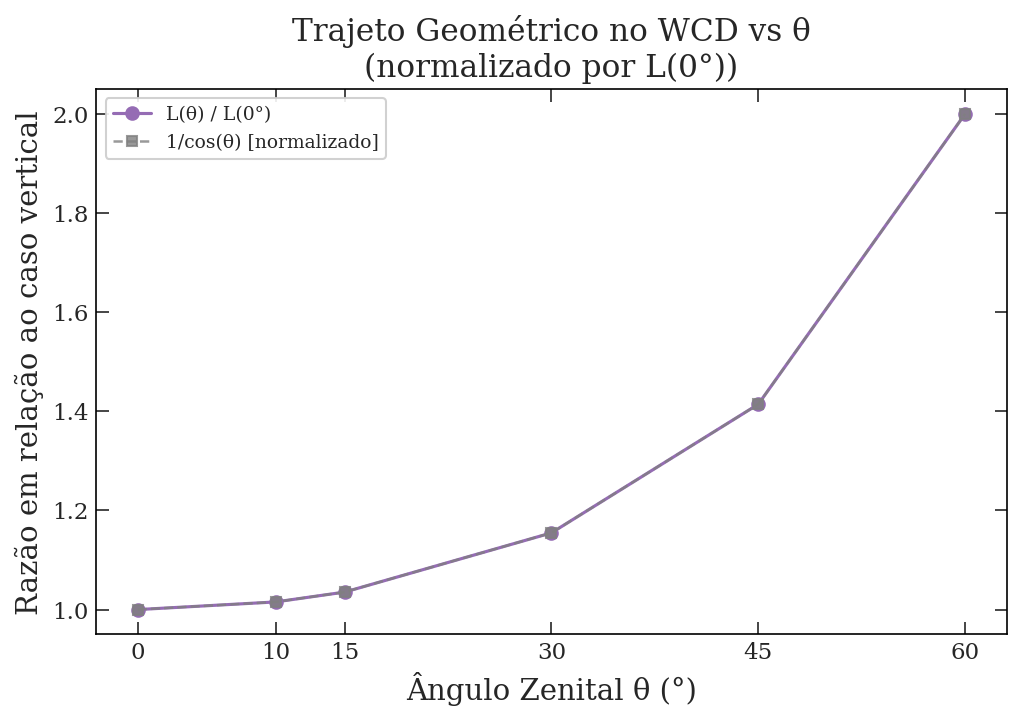

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))

L_vals = [caminho_por_angulo(a) for a in angulos_list]
cos_inv = [1 / np.cos(np.radians(a)) for a in angulos_list]

# Normaliza pelo valor vertical para comparar na mesma escala
L_norm       = [L / L_vals[0] for L in L_vals]
cos_inv_norm = [c / cos_inv[0] for c in cos_inv]

ax.plot(angulos_list, L_norm,       'o-',  color=palette[4], linewidth=1.5, markersize=6, label='L(θ) / L(0°)')
ax.plot(angulos_list, cos_inv_norm, 's--', color='gray',     linewidth=1.2, markersize=5, alpha=0.8, label='1/cos(θ) [normalizado]')

ax.set_xlabel('Ângulo Zenital θ (°)')
ax.set_ylabel('Razão em relação ao caso vertical')
ax.set_title('Trajeto Geométrico no WCD vs θ\n(normalizado por L(0°))')
ax.set_xticks(angulos_list)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('angular_trajeto_geometrico.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_trajeto_geometrico.pdf', bbox_inches='tight')
plt.show()

## 8. Sobreposição das Distribuições — Comparação Direta

Todas as distribuições de energia depositada sobrepostas no mesmo plot para comparação visual.

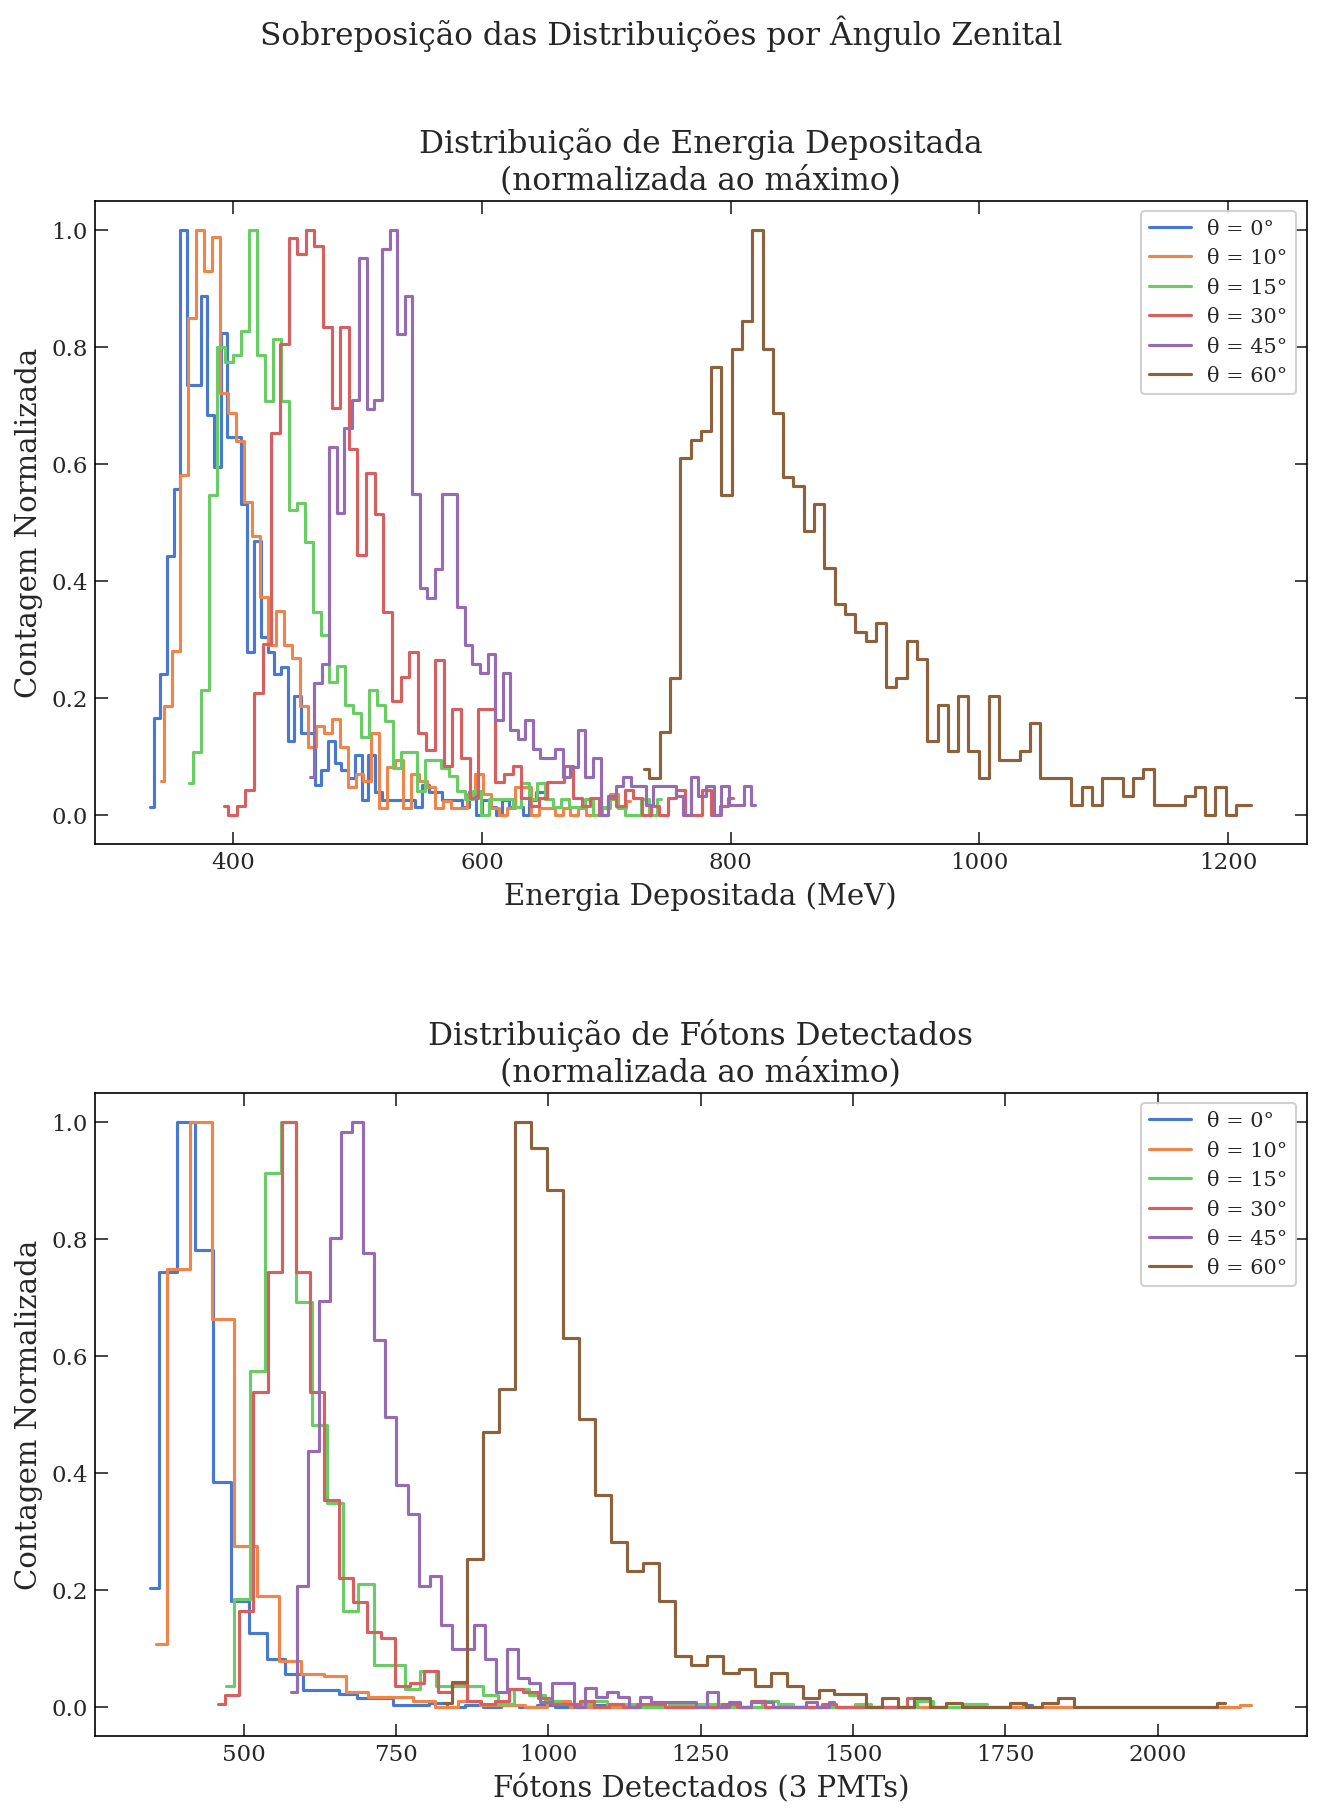

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(9, 12))

# ── Energia depositada — sobreposição ──────────────────────────────────────
ax1 = axes[0]
for ang in angulos_list:
    edep = dados[ang]['df']['EnergyDeposited_MeV']
    edep_filt = edep[edep < edep.mean() + 3 * edep.std()]
    counts, edges = np.histogram(edep_filt, bins=60)
    centers = (edges[:-1] + edges[1:]) / 2
    # Normaliza para comparação de forma
    counts_norm = counts / counts.max()
    ax1.step(centers, counts_norm, where='mid',
             color=CORES_ANGULO[ang], linewidth=1.5, label=f'θ = {ang}°')
ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Contagem Normalizada')
ax1.set_title('Distribuição de Energia Depositada\n(normalizada ao máximo)')
ax1.legend(fontsize=10)

# ── Fótons detectados — sobreposição ──────────────────────────────────────
ax2 = axes[1]
for ang in angulos_list:
    total = dados[ang]['df_pmt']['nFotonsTotal']
    counts, edges = np.histogram(total, bins=50)
    centers = (edges[:-1] + edges[1:]) / 2
    counts_norm = counts / counts.max()
    ax2.step(centers, counts_norm, where='mid',
             color=CORES_ANGULO[ang], linewidth=1.5, label=f'θ = {ang}°')
ax2.set_xlabel('Fótons Detectados (3 PMTs)')
ax2.set_ylabel('Contagem Normalizada')
ax2.set_title('Distribuição de Fótons Detectados\n(normalizada ao máximo)')
ax2.legend(fontsize=10)

plt.suptitle('Sobreposição das Distribuições por Ângulo Zenital', fontsize=15, y=1.01)
plt.tight_layout(h_pad=4)
plt.savefig('angular_sobreposicao.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_sobreposicao.pdf', bbox_inches='tight')
plt.show()

## 9. Hodoscópio — Deslocamento do Hit com o Ângulo

Para um múon inclinado, o ponto de entrada no hodoscópio deve deslocar-se do centro.  
Este é um dos principais critérios de verificação dos ângulos maiores.

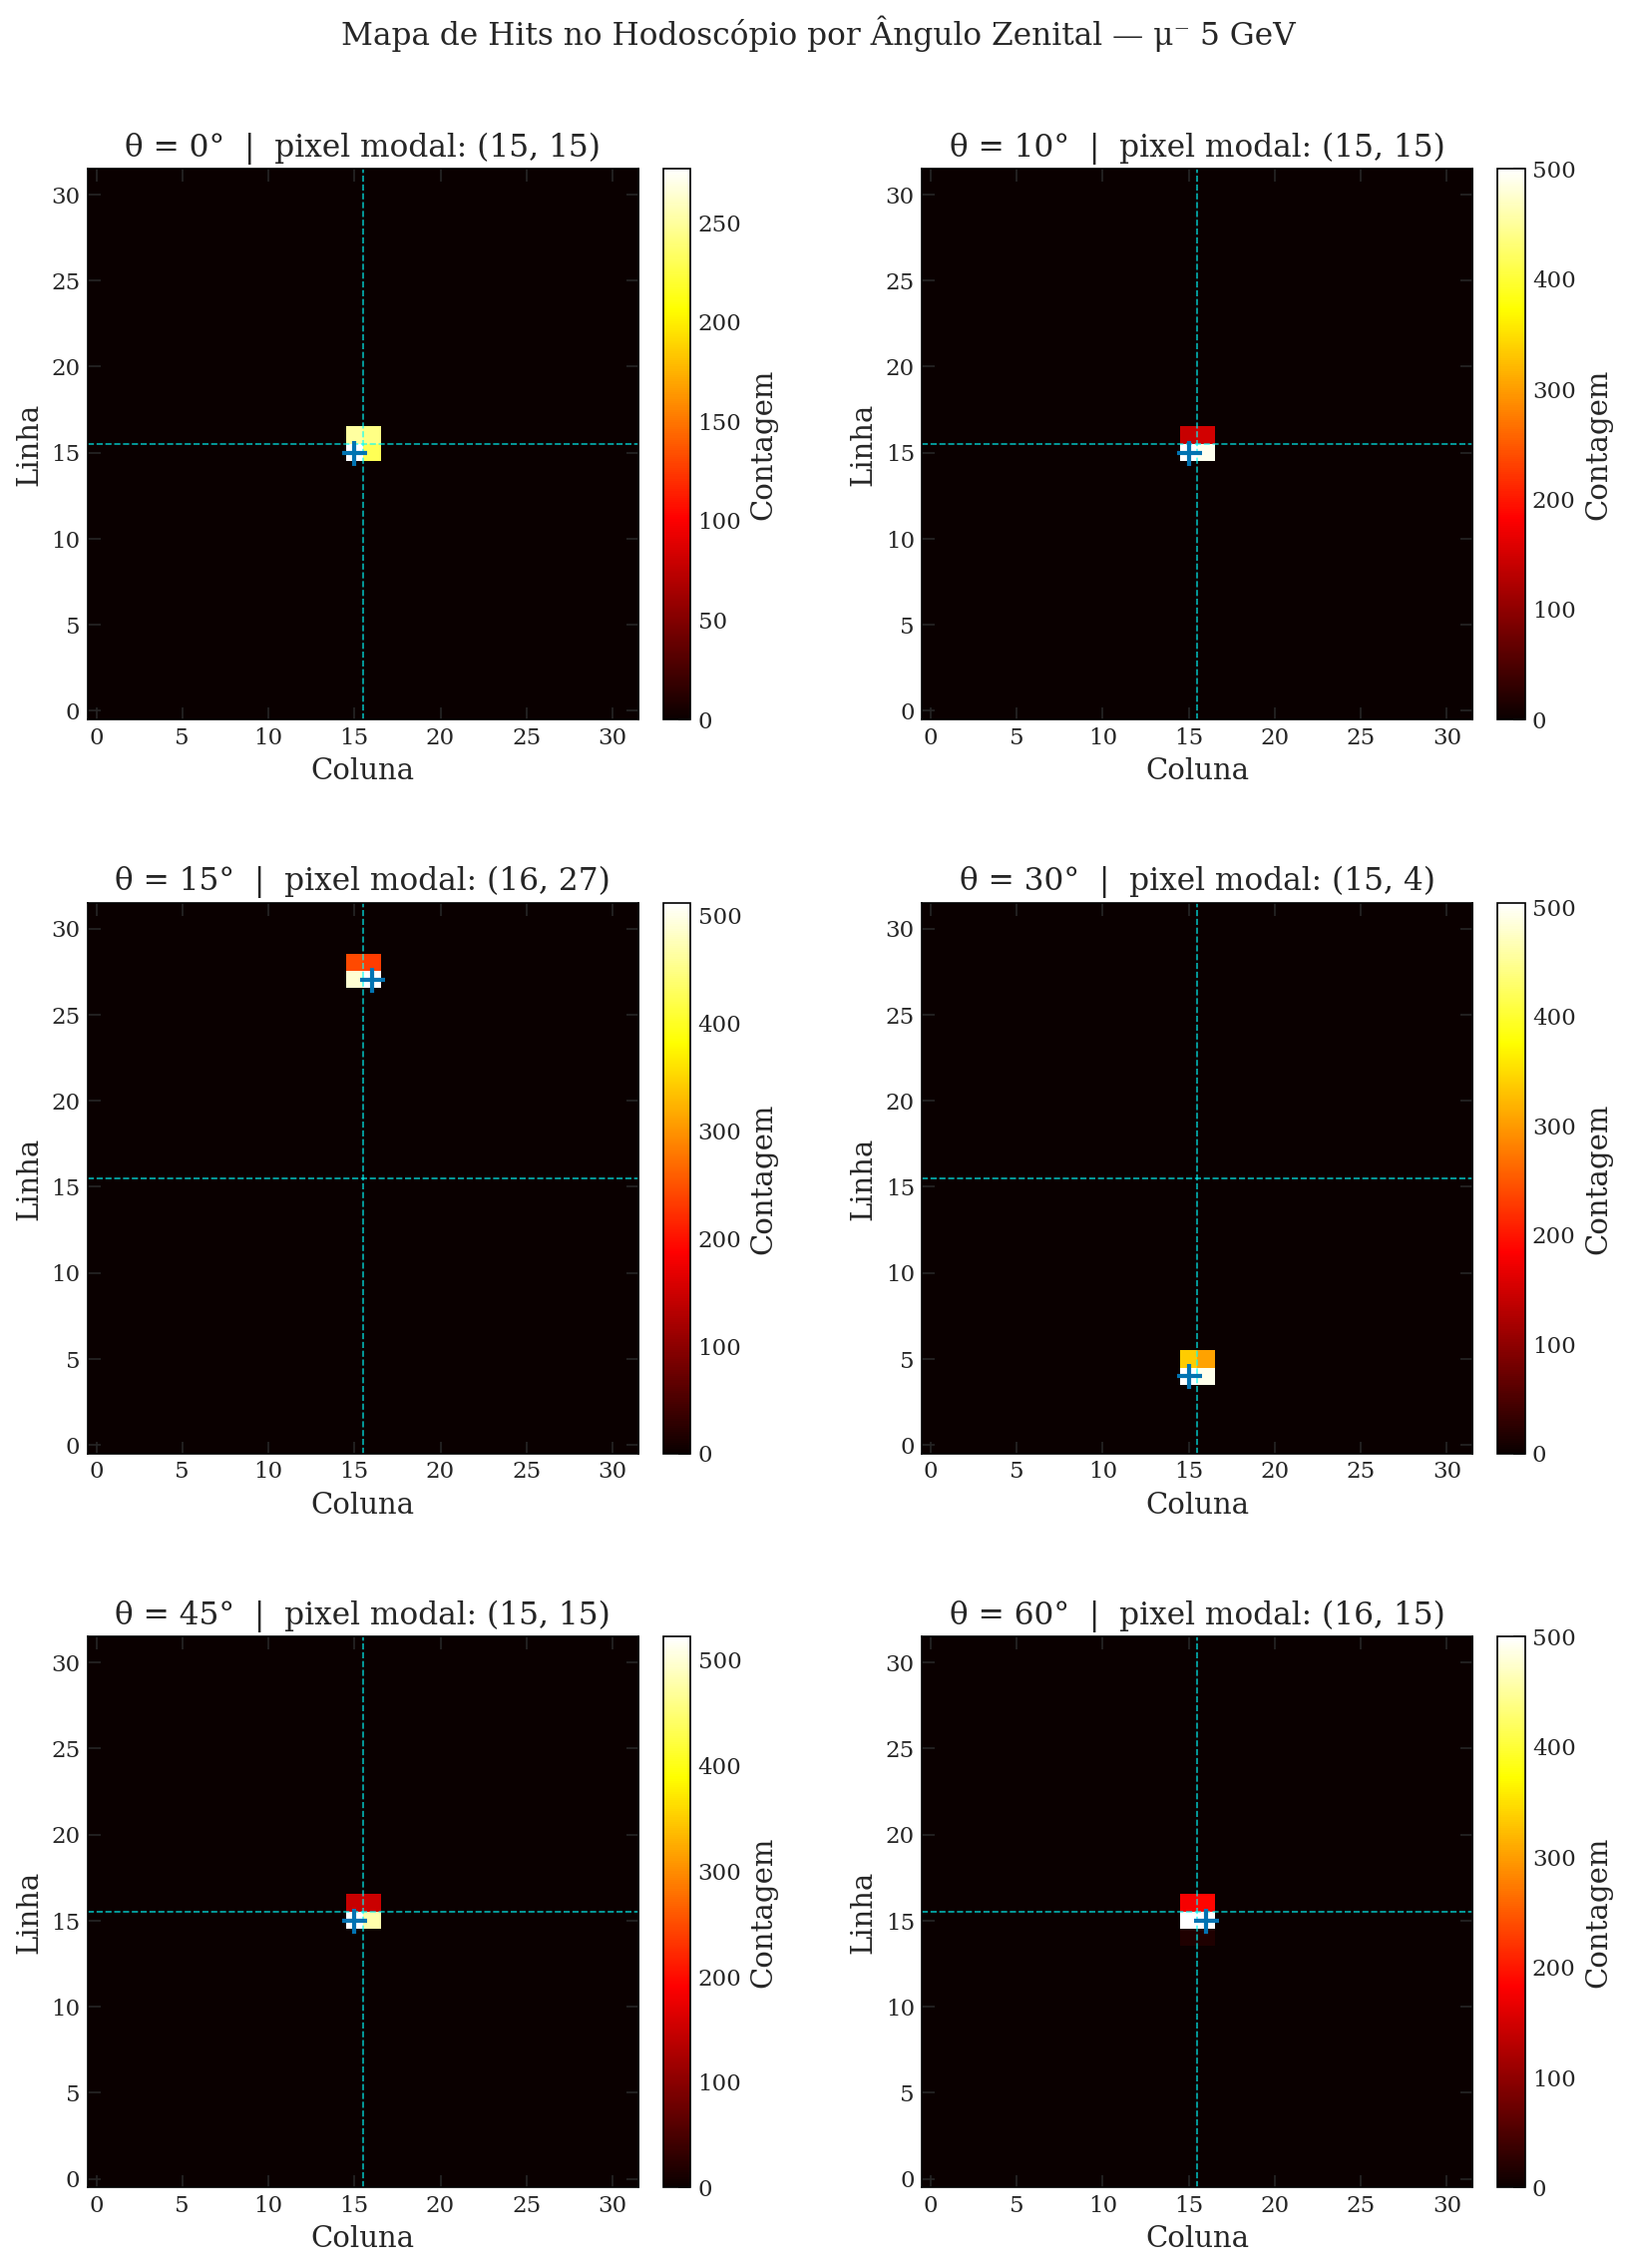


Deslocamento do hit central em relação ao píxel (15, 15):
    θ |  Col modal | Linha modal |   ΔCol |  ΔLinha
--------------------------------------------------
   0° |         15 |          15 |      0 |       0
  10° |         15 |          15 |      0 |       0
  15° |         16 |          27 |      1 |      12
  30° |         15 |           4 |      0 |     -11
  45° |         15 |          15 |      0 |       0
  60° |         16 |          15 |      1 |       0


In [11]:
fig, axes = plt.subplots(3, 2, figsize=(11, 15))
axes = axes.flatten()

for i, ang in enumerate(sorted(dados.keys())):
    ax = axes[i]
    df_hodo = dados[ang]['df_hodo']

    heatmap = np.zeros((32, 32))
    for _, row in df_hodo.iterrows():
        c, r = int(row['ColumnID']), int(row['RowID'])
        if 0 <= r < 32 and 0 <= c < 32:
            heatmap[r, c] += 1

    im = ax.imshow(heatmap, cmap='hot', origin='lower')
    plt.colorbar(im, ax=ax, label='Contagem', fraction=0.046, pad=0.04)

    # Centro geométrico
    ax.axvline(x=15.5, color='cyan', linewidth=0.8, linestyle='--', alpha=0.7)
    ax.axhline(y=15.5, color='cyan', linewidth=0.8, linestyle='--', alpha=0.7)

    # Pixel mais atingido
    col_mode = df_hodo['ColumnID'].mode()[0]
    row_mode = df_hodo['RowID'].mode()[0]
    ax.plot(col_mode, row_mode, 'b+', markersize=12, markeredgewidth=2)

    ax.set_xlabel('Coluna')
    ax.set_ylabel('Linha')
    ax.set_title(f'θ = {ang}°  |  pixel modal: ({col_mode}, {row_mode})')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Mapa de Hits no Hodoscópio por Ângulo Zenital — μ⁻ 5 GeV', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('angular_hodoscopio.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_hodoscopio.pdf', bbox_inches='tight')
plt.show()

print('\nDeslocamento do hit central em relação ao píxel (15, 15):')
print(f'{"θ":>5} | {"Col modal":>10} | {"Linha modal":>11} | {"ΔCol":>6} | {"ΔLinha":>7}')
print('-' * 50)
for ang in sorted(dados.keys()):
    dh = dados[ang]['df_hodo']
    cm = dh['ColumnID'].mode()[0]
    rm = dh['RowID'].mode()[0]
    print(f'{ang:>4}° | {cm:>10} | {rm:>11} | {cm-15:>6} | {rm-15:>7}')

## 10. Normalização pelo Comprimento do Trajeto

Verificamos se a energia por centímetro de trajeto (dE/dx) é constante — conforme esperado para MIP.

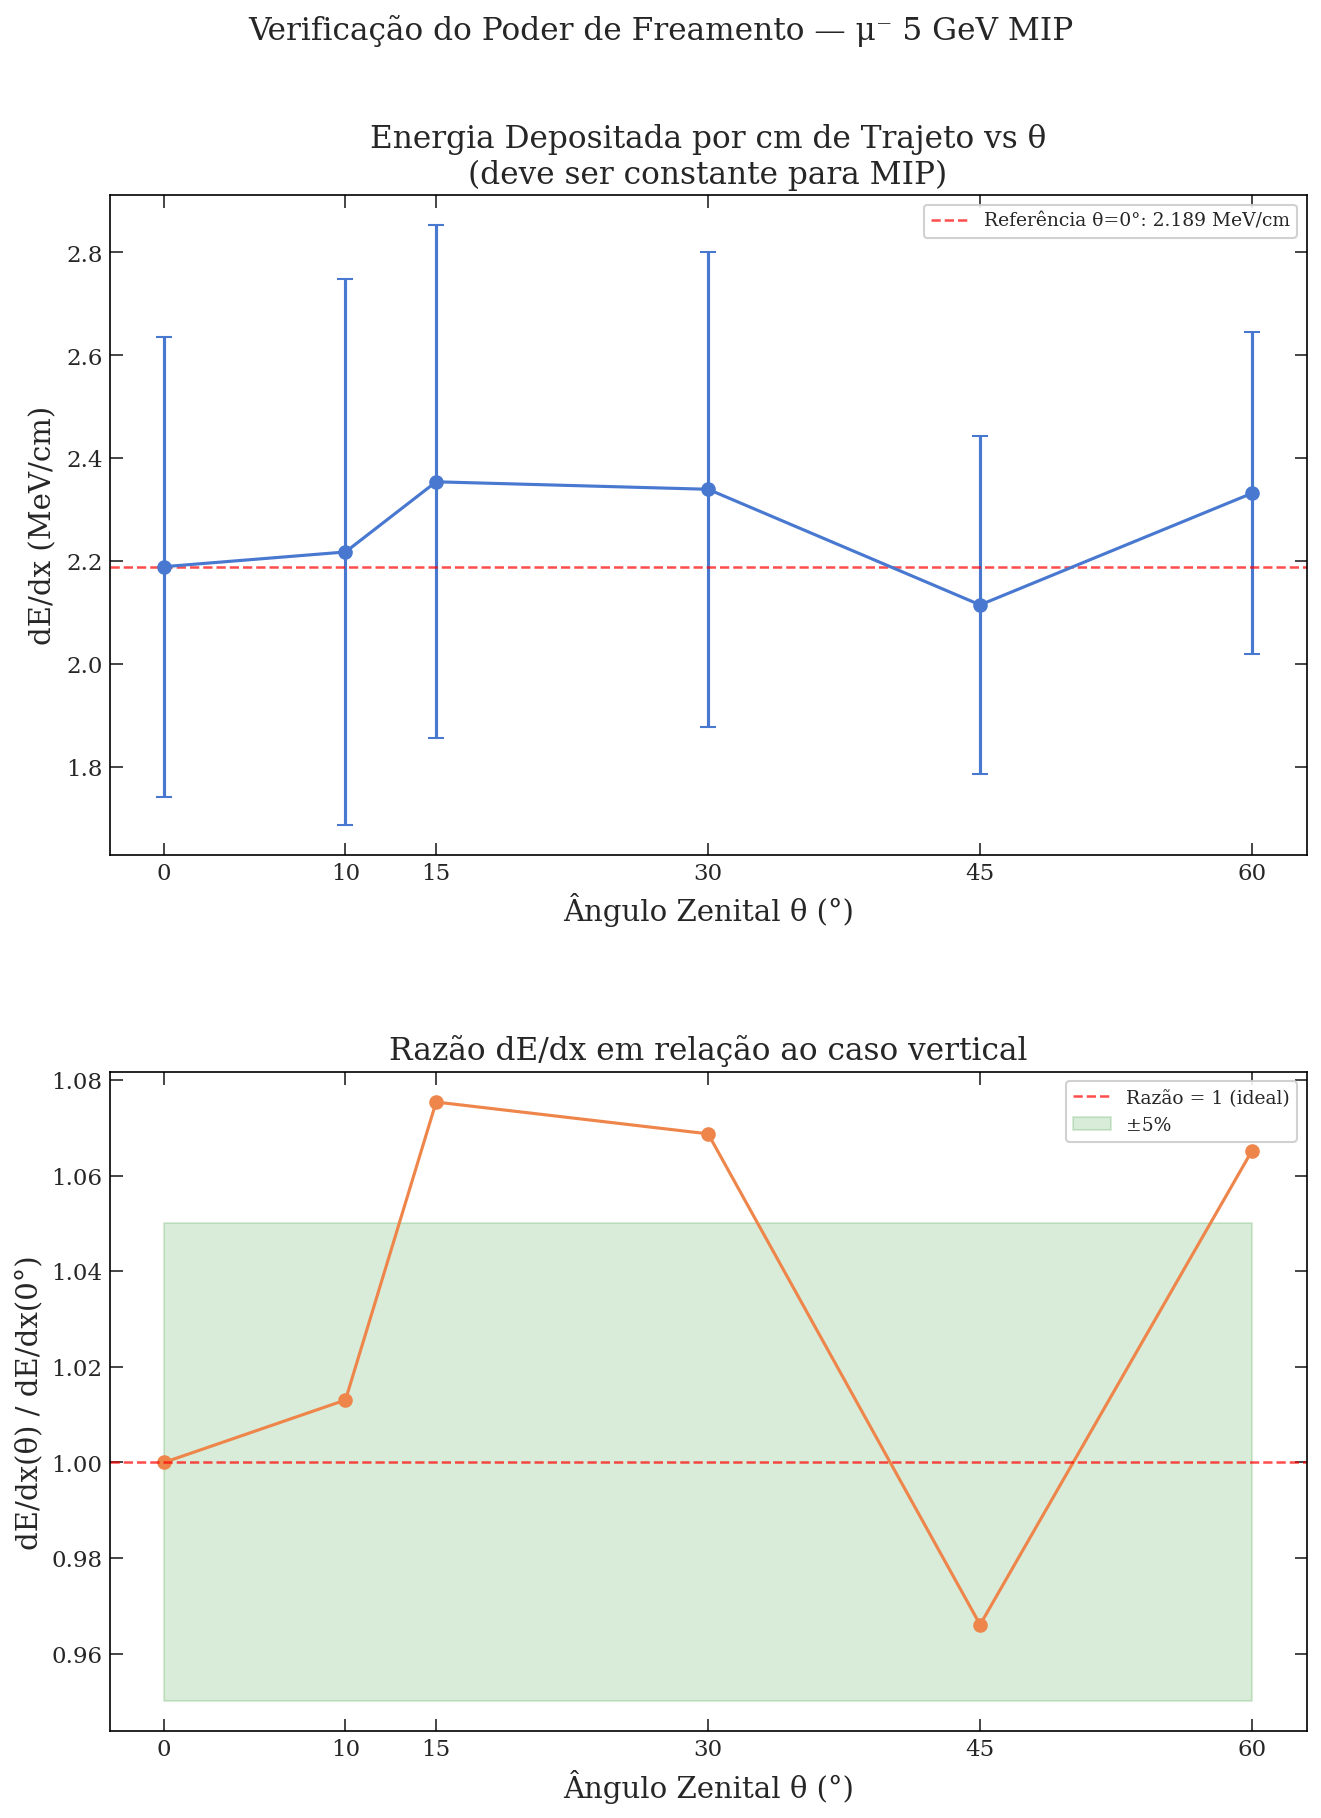


dE/dx por ângulo:
  θ =  0°:  2.1890 ± 0.4470 MeV/cm
  θ = 10°:  2.2176 ± 0.5302 MeV/cm
  θ = 15°:  2.3540 ± 0.4988 MeV/cm
  θ = 30°:  2.3395 ± 0.4618 MeV/cm
  θ = 45°:  2.1147 ± 0.3289 MeV/cm
  θ = 60°:  2.3318 ± 0.3132 MeV/cm


In [12]:
fig, axes = plt.subplots(2, 1, figsize=(9, 12))

edep_norm_means = []
edep_norm_stds  = []

for ang in angulos_list:
    L = caminho_por_angulo(ang)
    edep_por_cm = dados[ang]['df']['EnergyDeposited_MeV'] / L
    edep_norm_means.append(edep_por_cm.mean())
    edep_norm_stds.append(edep_por_cm.std())

# Plot dE/dx por ângulo
ax1 = axes[0]
ax1.errorbar(angulos_list, edep_norm_means, yerr=edep_norm_stds,
             fmt='o-', color=palette[0], capsize=4, linewidth=1.5, markersize=6)
ax1.axhline(y=edep_norm_means[0], color='red', linestyle='--',
            linewidth=1.2, alpha=0.7, label=f'Referência θ=0°: {edep_norm_means[0]:.3f} MeV/cm')
ax1.set_xlabel('Ângulo Zenital θ (°)')
ax1.set_ylabel('dE/dx (MeV/cm)')
ax1.set_title('Energia Depositada por cm de Trajeto vs θ\n(deve ser constante para MIP)')
ax1.set_xticks(angulos_list)
ax1.legend(fontsize=9)

# Razão em relação ao valor vertical
ax2 = axes[1]
razao = [m / edep_norm_means[0] for m in edep_norm_means]
ax2.plot(angulos_list, razao, 'o-', color=palette[1], linewidth=1.5, markersize=6)
ax2.axhline(y=1.0, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Razão = 1 (ideal)')
ax2.fill_between(angulos_list, 0.95, 1.05, alpha=0.15, color='green', label='±5%')
ax2.set_xlabel('Ângulo Zenital θ (°)')
ax2.set_ylabel('dE/dx(θ) / dE/dx(0°)')
ax2.set_title('Razão dE/dx em relação ao caso vertical')
ax2.set_xticks(angulos_list)
ax2.legend(fontsize=9)

plt.suptitle('Verificação do Poder de Freamento — μ⁻ 5 GeV MIP', fontsize=15, y=1.01)
plt.tight_layout(h_pad=4)
plt.savefig('angular_dedx.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_dedx.pdf', bbox_inches='tight')
plt.show()

print('\ndE/dx por ângulo:')
for ang, m, s in zip(angulos_list, edep_norm_means, edep_norm_stds):
    print(f'  θ = {ang:2d}°:  {m:.4f} ± {s:.4f} MeV/cm')

## 11. Assimetria das PMTs por Ângulo

Para o múon vertical central, as três PMTs de fundo devem responder de forma simétrica.
Com inclinação, a assimetria aumenta — um múon inclinado ilumina as PMTs de forma diferente
dependendo da direção azimutal. Este plot é essencial para verificar ângulos grandes.

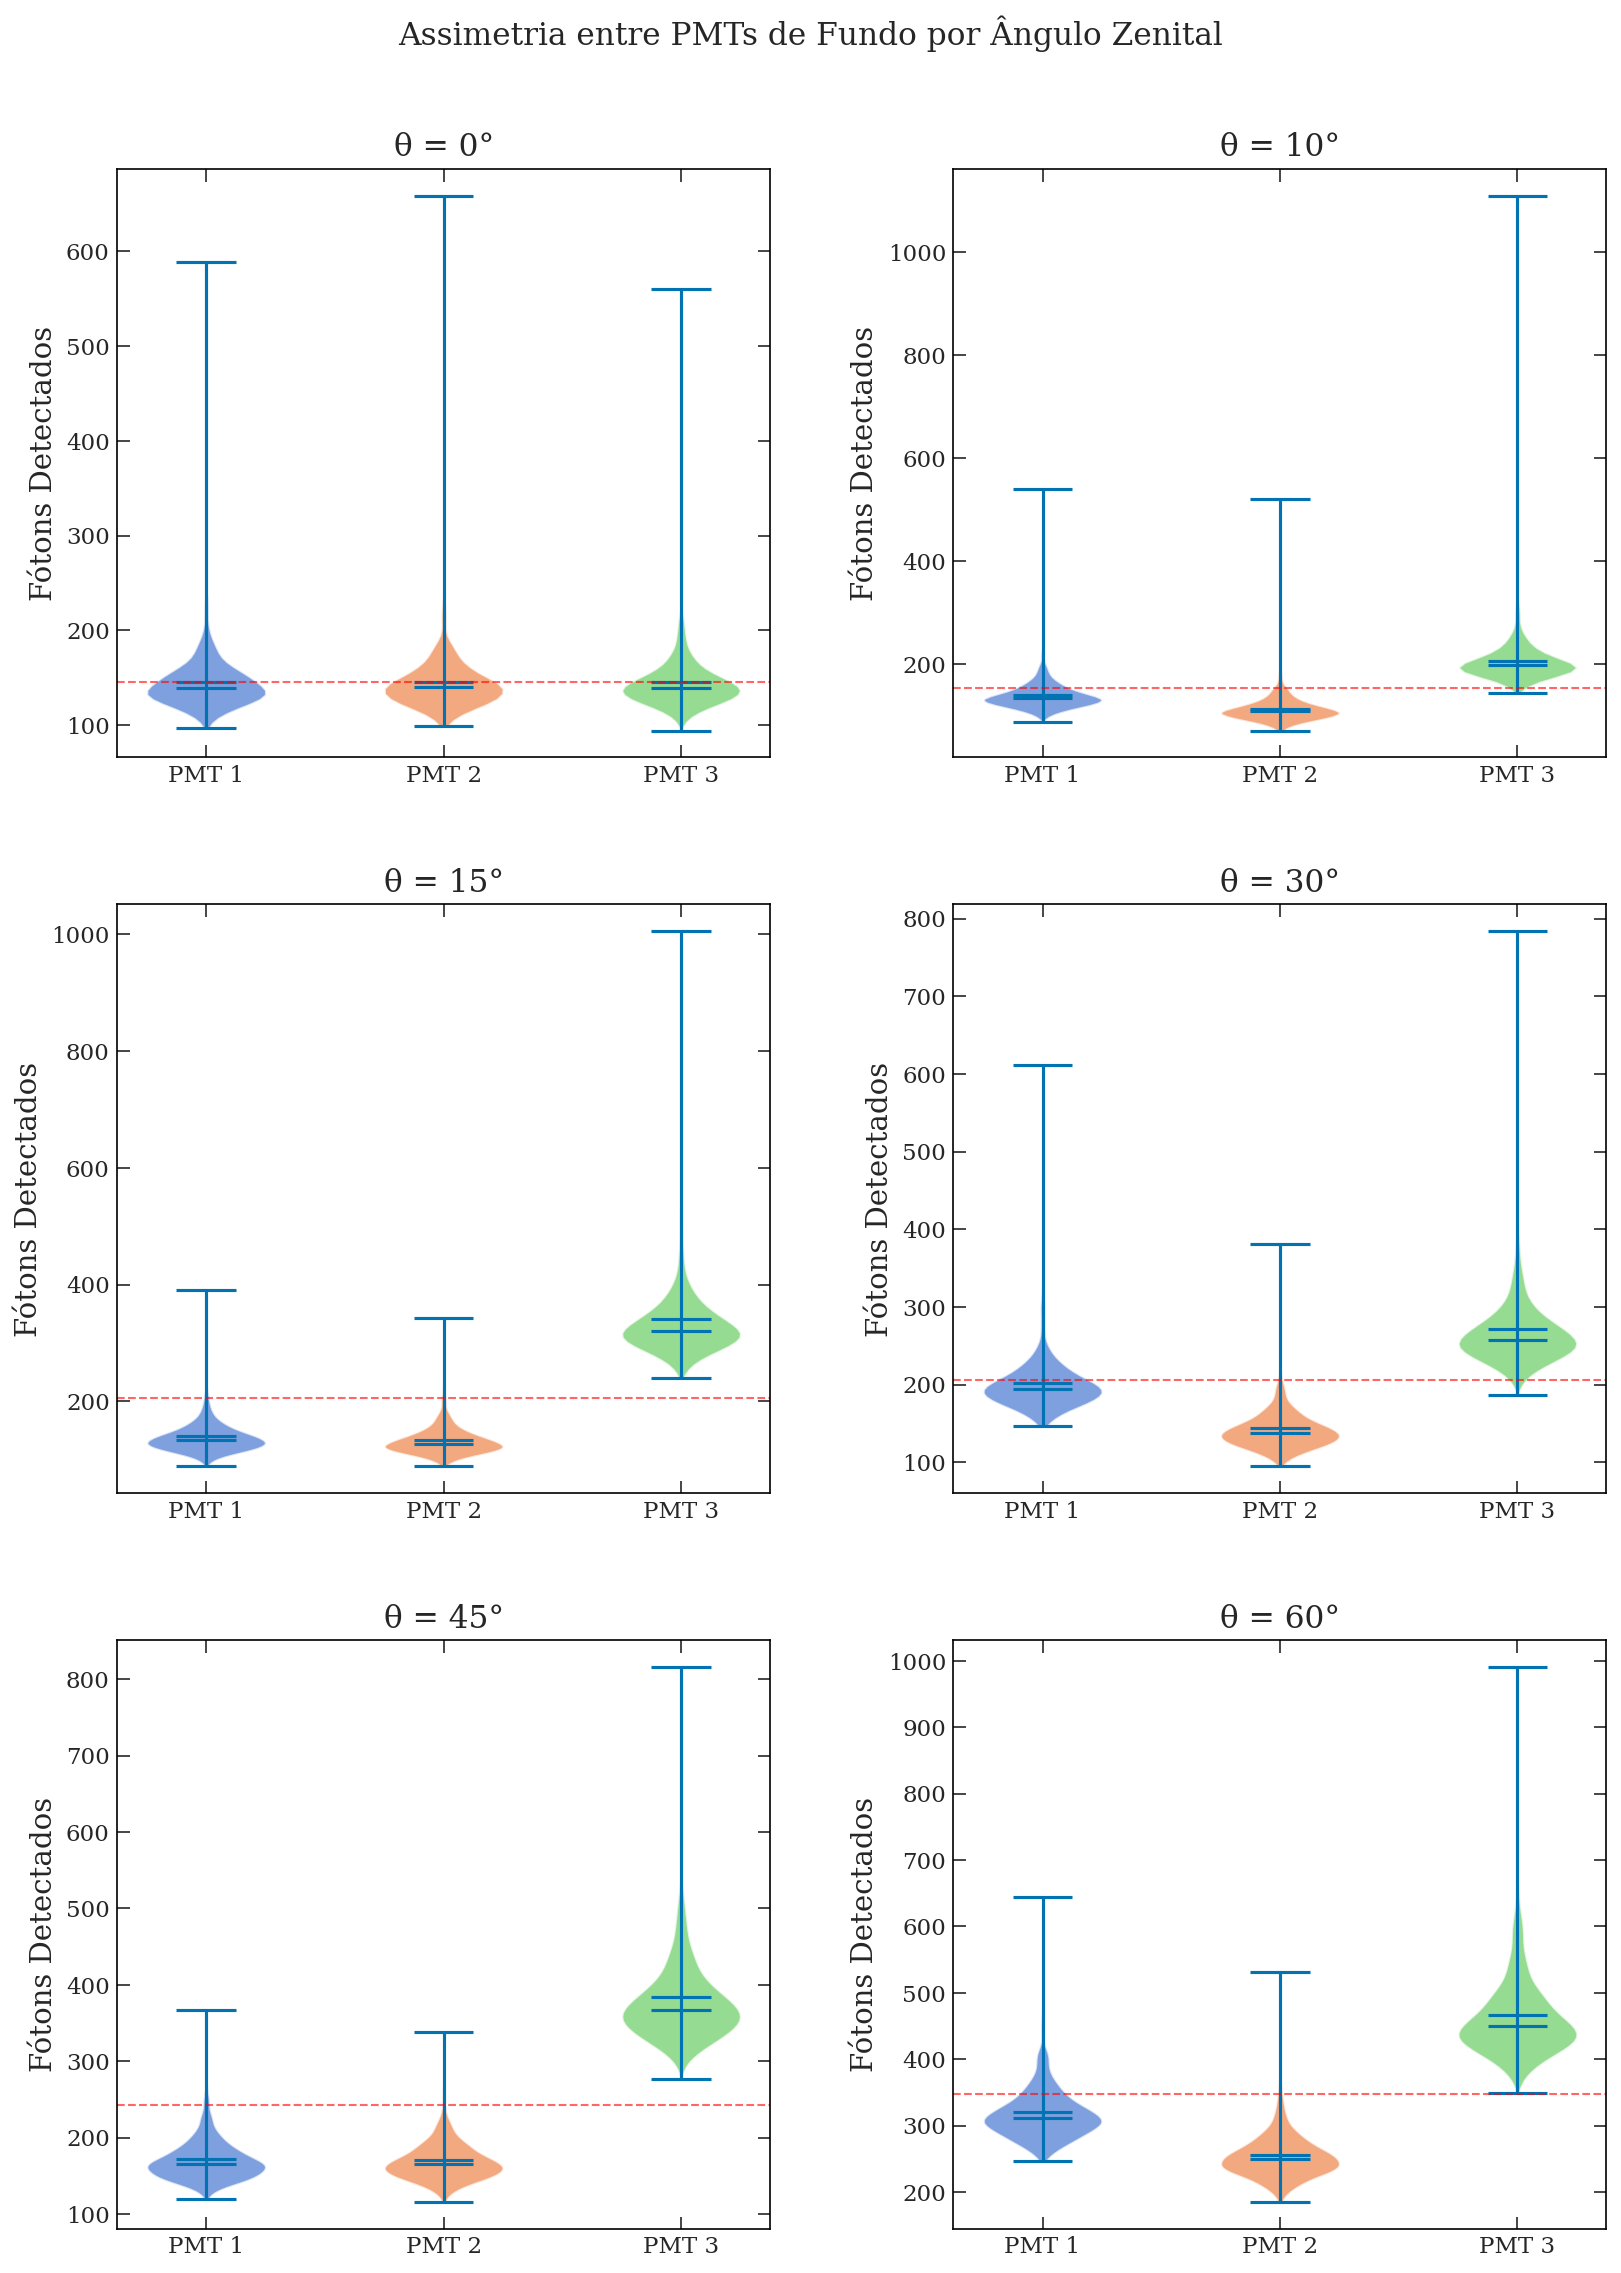

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(11, 15))
axes = axes.flatten()

for i, ang in enumerate(sorted(dados.keys())):
    ax = axes[i]
    df_pmt = dados[ang]['df_pmt']
    data_v = [df_pmt['nFotonsPMT1'], df_pmt['nFotonsPMT2'], df_pmt['nFotonsPMT3']]
    vp = ax.violinplot(data_v, positions=[1, 2, 3], showmeans=True, showmedians=True)
    cores_pmts = [palette[0], palette[1], palette[2]]
    for j, pc in enumerate(vp['bodies']):
        pc.set_facecolor(cores_pmts[j])
        pc.set_alpha(0.7)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(['PMT 1', 'PMT 2', 'PMT 3'])
    ax.set_ylabel('Fótons Detectados')
    ax.set_title(f'θ = {ang}°')
    # Linha da média
    media = df_pmt[['nFotonsPMT1','nFotonsPMT2','nFotonsPMT3']].values.mean()
    ax.axhline(media, color='red', linestyle='--', linewidth=1, alpha=0.6)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Assimetria entre PMTs de Fundo por Ângulo Zenital', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('angular_assimetria_pmts.png', dpi=300, bbox_inches='tight')
plt.savefig('angular_assimetria_pmts.pdf', bbox_inches='tight')
plt.show()

## 12. Resumo Quantitativo da Análise Angular

In [14]:
print('=' * 90)
print('RESUMO QUANTITATIVO — ANÁLISE ANGULAR SWGO')
print(f'Partícula: μ⁻  |  Energia: 5 GeV  |  Detector: WCD (r=170 cm, h=187.87 cm)')
print('=' * 90)

cols = ['angulo', 'L_cm', 'edep_mean', 'edep_std', 'cer_mean', 'total_mean', 'ef_mean']
labels = ['θ (°)', 'L (cm)', 'Edep média (MeV)', 'Edep std', 'Cer. total', 'PMTs total', 'Efic. (%)']
df_print = df_resumo[cols].copy()
df_print.columns = labels
df_print = df_print.round(2)
print(df_print.to_string(index=False))
print('=' * 90)

# Variação em relação ao caso vertical
if 0 in df_resumo['angulo'].values:
    ref = df_resumo[df_resumo['angulo'] == 0].iloc[0]
    print('\nVariação relativa em relação ao caso vertical (θ = 0°):')
    print(f'{"θ":>5} | {"ΔEdep (%)": >12} | {"ΔCerenkov (%)": >14} | {"ΔPMT total (%)": >15} | {"ΔEfic. (pp)":>12}')
    print('-' * 65)
    for _, row in df_resumo.iterrows():
        if row['angulo'] == 0:
            continue
        delta_edep = (row['edep_mean'] - ref['edep_mean']) / ref['edep_mean'] * 100
        delta_cer  = (row['cer_mean']  - ref['cer_mean'])  / ref['cer_mean']  * 100
        delta_pmt  = (row['total_mean']- ref['total_mean'])/ ref['total_mean']* 100
        delta_ef   = row['ef_mean'] - ref['ef_mean']
        print(f'{row["angulo"]:>4}° | {delta_edep:>+11.1f}% | {delta_cer:>+13.1f}% | {delta_pmt:>+14.1f}% | {delta_ef:>+11.2f} pp')

RESUMO QUANTITATIVO — ANÁLISE ANGULAR SWGO
Partícula: μ⁻  |  Energia: 5 GeV  |  Detector: WCD (r=170 cm, h=187.87 cm)
 θ (°)  L (cm)  Edep média (MeV)  Edep std  Cer. total  PMTs total  Efic. (%)
     0  187.87            411.25     83.99    74742.34      436.45       0.58
    10  190.77            423.05    101.15    76202.61      461.58       0.62
    15  194.50            457.86     97.01    82496.00      616.35       0.74
    30  216.93            507.51    100.18    91593.77      617.89       0.67
    45  265.69            561.85     87.38   101763.66      726.76       0.71
    60  375.74            876.16    117.68   158387.57     1042.65       0.66

Variação relativa em relação ao caso vertical (θ = 0°):
    θ |    ΔEdep (%) |  ΔCerenkov (%) |  ΔPMT total (%) |  ΔEfic. (pp)
-----------------------------------------------------------------
10.0° |        +2.9% |          +2.0% |           +5.8% |       +0.04 pp
15.0° |       +11.3% |         +10.4% |          +41.2% |       +0.16

---
**Fim da análise angular.** 
Consulte os plots salvos: `angular_energia_depositada.png`, `angular_fotons_pmt.png`,
`angular_evolucao_grandezas.png`, `angular_sobreposicao.png`, `angular_hodoscopio.png`,
`angular_dedx.png`, `angular_assimetria_pmts.png`.